# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import re

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torch.optim import Adam

from datasets import load_dataset
from collections import Counter
from NADE import NADE

EPOCHS = 15
D_TXT = 100
H_TXT = 50
LR = 1e-3

# Pick GPU automatically if available, otherwise CPU — every later cell reuses `device`.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())
print("Using device    :", device)

c:\Users\alira\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version : 2.6.0+cu124
CUDA available  : True
Using device    : cuda


# Dataset

In [2]:
dataset = load_dataset("ucirvine/sms_spam")

In [3]:
dataset.keys()

print('column names: ', dataset['train'].column_names)
print('first row : ', dataset['train'][0])

column names:  ['sms', 'label']
first row :  {'sms': 'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...\n', 'label': 0}


In [4]:
dataset['train']['sms'][:4]

['Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...\n',
 'Ok lar... Joking wif u oni...\n',
 "Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's\n",
 'U dun say so early hor... U c already then say...\n']

In [5]:
def clean_text(sms):
    clean_sms = []
    
    for text in sms:
        clean_text = re.sub(r"[^a-zA-Z\s]", "", text)
        clean_text = clean_text.lower().split()
        clean_sms.append(clean_text)
    
    return clean_sms

In [6]:
X = clean_text(dataset['train']['sms'])
X[0]

['go',
 'until',
 'jurong',
 'point',
 'crazy',
 'available',
 'only',
 'in',
 'bugis',
 'n',
 'great',
 'world',
 'la',
 'e',
 'buffet',
 'cine',
 'there',
 'got',
 'amore',
 'wat']

## Vocabulary creation
top 100 most frequent words

In [7]:
def get_freqs(x):
    counter = Counter()
    
    for sms in x:
        counter.update(sms)
    
    return counter

In [8]:
freqs = get_freqs(X)
freqs

Counter({'to': 2251,
         'i': 2249,
         'you': 2128,
         'a': 1448,
         'the': 1334,
         'u': 1156,
         'and': 971,
         'is': 893,
         'in': 891,
         'me': 791,
         'my': 759,
         'for': 711,
         'your': 677,
         'it': 622,
         'of': 622,
         'call': 581,
         'have': 576,
         'on': 536,
         'that': 514,
         'are': 490,
         'now': 479,
         'im': 476,
         'so': 439,
         'not': 436,
         'but': 432,
         'or': 417,
         'at': 405,
         'can': 405,
         'do': 401,
         'ur': 390,
         'get': 390,
         'be': 385,
         'will': 383,
         'if': 383,
         'with': 382,
         'just': 368,
         'no': 352,
         'we': 351,
         'this': 330,
         'its': 315,
         'up': 307,
         'dont': 298,
         'when': 287,
         'go': 285,
         'from': 279,
         'ok': 278,
         'free': 278,
         'ltgt': 276,


In [9]:
vocab = [word for word, count in freqs.most_common(100)]
# len(vocab)
vocab

['to',
 'i',
 'you',
 'a',
 'the',
 'u',
 'and',
 'is',
 'in',
 'me',
 'my',
 'for',
 'your',
 'it',
 'of',
 'call',
 'have',
 'on',
 'that',
 'are',
 'now',
 'im',
 'so',
 'not',
 'but',
 'or',
 'at',
 'can',
 'do',
 'ur',
 'get',
 'be',
 'will',
 'if',
 'with',
 'just',
 'no',
 'we',
 'this',
 'its',
 'up',
 'dont',
 'when',
 'go',
 'from',
 'ok',
 'free',
 'ltgt',
 'all',
 'out',
 'how',
 'what',
 'know',
 'like',
 'ill',
 'got',
 'good',
 'then',
 'was',
 'am',
 'come',
 'only',
 'day',
 'time',
 'love',
 'there',
 'want',
 'send',
 'text',
 'he',
 'as',
 'by',
 'going',
 'one',
 'need',
 'about',
 'txt',
 'home',
 'lor',
 'see',
 'sorry',
 'stop',
 'still',
 'r',
 'back',
 'our',
 'n',
 'reply',
 'today',
 'mobile',
 'tell',
 'new',
 'well',
 'hi',
 'later',
 'think',
 'da',
 'been',
 'she',
 'please']

In [10]:
def binarize(x, vocab):
    x_set = set(x)
    return torch.tensor([1.0 if word in x_set else 0.0 for word in vocab])

In [11]:
def process_dataset(dataset):
    processed_txt = clean_text(dataset['train']['sms'])
    freqs = get_freqs(processed_txt)
    vocab = [word for word, count in freqs.most_common(100)]
    
    X = torch.stack([binarize(sms, vocab) for sms in processed_txt])
    y = torch.tensor(dataset['train']['label'])
    
    return X, y, vocab, freqs

In [12]:
X, y, vocab, freqs = process_dataset(dataset)

print("Dataset shape:", X.shape)
print('lables:       ', y.shape)

Dataset shape: torch.Size([5574, 100])
lables:        torch.Size([5574])


In [13]:
# Filter normal (label 0) and spam (label 1) messages
X_normal = X[y == 0]
X_spam = X[y == 1]

# Create dataset with normal messages only
normal_dataset = TensorDataset(X_normal)

train_size = int(0.8 * len(normal_dataset))
test_size = len(normal_dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_dataset, test_dataset = random_split(
    normal_dataset,
    [train_size, test_size],
    generator=generator
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Normal Train: {len(train_dataset)} | Normal Test: {len(test_dataset)} | Spam Set: {len(X_spam)}")

Normal Train: 3861 | Normal Test: 966 | Spam Set: 747


# Training

In [17]:
def text_train_loop(train_loader, model, optimizer, epochs=EPOCHS, device= "cpu"):
    model.train()
    surprise_history = []  # Stores average surprise per epoch

    for epoch in range(1, epochs + 1):
        total_loss = 0.0

        for (inputs,) in train_loader:
            inputs = inputs.to(device)

            optimizer.zero_grad()

            # 2. Calculate average surprise loss
            loss = model.compute_surprise(inputs)

            # 3. Compute gradients and update weights
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        # Compute average loss for the current epoch
        avg_loss = total_loss / len(train_loader)
        surprise_history.append(avg_loss)
        print(f"Epoch [{epoch}/{epochs}] - Loss (Surprise): {avg_loss:.4f}")

    return surprise_history

In [18]:
txt_model = NADE(D_TXT, H_TXT)
txt_model = txt_model.to(device)
# criterion = nn.BCEWithLogitsLoss()
optimizer = Adam(txt_model.parameters(), lr= LR)

In [19]:
superise_history = text_train_loop(
    train_loader,
    txt_model,
    optimizer,
    EPOCHS,
    device
)

Epoch [1/15] - Loss (Surprise): 1.1053
Epoch [2/15] - Loss (Surprise): 0.4938
Epoch [3/15] - Loss (Surprise): 0.3207
Epoch [4/15] - Loss (Surprise): 0.2746
Epoch [5/15] - Loss (Surprise): 0.2586
Epoch [6/15] - Loss (Surprise): 0.2502
Epoch [7/15] - Loss (Surprise): 0.2445
Epoch [8/15] - Loss (Surprise): 0.2398
Epoch [9/15] - Loss (Surprise): 0.2355
Epoch [10/15] - Loss (Surprise): 0.2321
Epoch [11/15] - Loss (Surprise): 0.2287
Epoch [12/15] - Loss (Surprise): 0.2258
Epoch [13/15] - Loss (Surprise): 0.2232
Epoch [14/15] - Loss (Surprise): 0.2206
Epoch [15/15] - Loss (Surprise): 0.2183


In [20]:
with torch.no_grad():
    samples = txt_model.sample(num_samples= 10)

print("Samples shape:", samples.shape)  # Should be (5, 100)
print("First generated binary vector:\n", samples[0])

Samples shape: torch.Size([10, 100])
First generated binary vector:
 tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 1., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')


In [21]:
# Convert vocabulary list to a NumPy array for fast boolean masking
vocab_np = np.array(vocab)

samples_np = samples.cpu().numpy()

# Decode each generated binary vector
for idx, sample in enumerate(samples_np):
    # Vectorized indexing: select words where sample indicator is 1.0
    decoded_words = vocab_np[sample == 1.0].tolist()
    
    print(f"Generated Message {idx + 1}: {decoded_words}")

Generated Message 1: ['i', 'are', 'can']
Generated Message 2: ['for', 'at', 'home', 'she']
Generated Message 3: ['for', 'going']
Generated Message 4: ['you', 'a', 'is', 'your', 'of', 'or', 'at', 'all', 'he']
Generated Message 5: ['the']
Generated Message 6: ['to', 'i', 'a', 'and', 'me', 'are', 'now', 'im', 'can', 'send']
Generated Message 7: ['now', 'what', 'day', 'going', 'well']
Generated Message 8: ['u', 'do']
Generated Message 9: ['but', 'we', 'see', 'reply']
Generated Message 10: ['in', 'from', 'back']


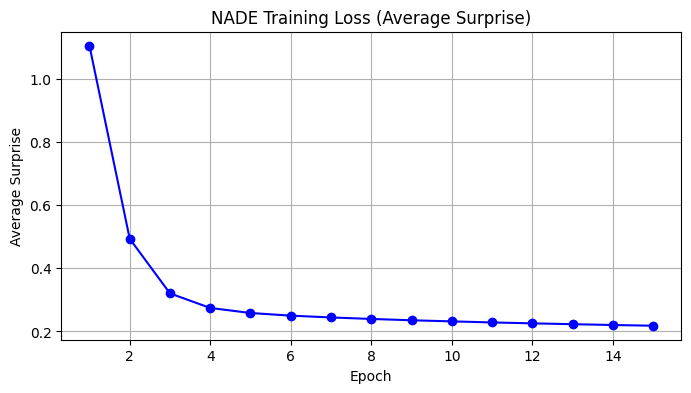

In [22]:
plt.figure(figsize= (8, 4))
plt.plot(
    range(1, len(superise_history) + 1),
    superise_history,
    marker = 'o',
    color = 'b'
)

plt.title("NADE Training Loss (Average Surprise)")
plt.xlabel("Epoch")
plt.ylabel("Average Surprise")
plt.grid(True)
plt.show()


In [23]:
def get_message_surprises(model, data_tensor, device):
    model.eval()
    with torch.no_grad():
        data_tensor = data_tensor.to(device)
        # Compute raw logits for all messages in the tensor
        logits = model(data_tensor)
        
        # Calculate surprise per feature, then take mean across the 100 word features
        surprise_per_message = F.binary_cross_entropy_with_logits(
            logits, data_tensor, reduction='none'
        ).mean(dim=1)
        
    return surprise_per_message.cpu().numpy()

# 1. Combine normal test batches into one tensor
normal_test_X = torch.cat([batch[0] for batch in test_loader])

# 2. Get surprise scores for both sets
normal_surprises = get_message_surprises(txt_model, normal_test_X, device)
spam_surprises = get_message_surprises(txt_model, X_spam, device)

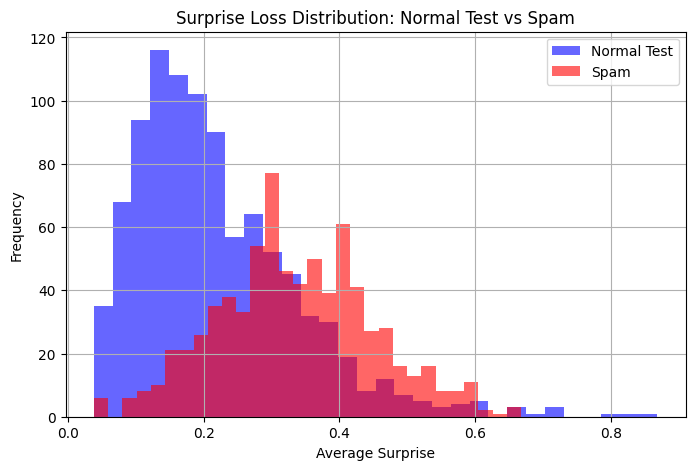

In [24]:
plt.figure(figsize=(8, 5))

# Overlay histograms for both groups
plt.hist(normal_surprises, bins=30, alpha=0.6, label='Normal Test', color='blue')
plt.hist(spam_surprises, bins=30, alpha=0.6, label='Spam', color='red')

plt.xlabel("Average Surprise")
plt.ylabel("Frequency")
plt.title("Surprise Loss Distribution: Normal Test vs Spam")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
# Frequency of each word in spam vs normal messages
spam_freq = X_spam.sum(dim=0) / len(X_spam)
normal_freq = X_normal.sum(dim=0) / len(X_normal)

# 1. Compute the difference in word frequencies (Spam frequency minus Normal frequency)
freq_diff = spam_freq - normal_freq

# 2. Extract indices of the top 10 largest positive differences
top10_indices = torch.topk(freq_diff, k=10).indices.cpu().numpy()

# 3. Map the indices back to words using our vocabulary array
top10_spam_words = vocab_np[top10_indices].tolist()

print("Top 10 words much more common in spam:", top10_spam_words)

Top 10 words much more common in spam: ['call', 'to', 'your', 'free', 'a', 'or', 'txt', 'now', 'for', 'mobile']


# Is spam more surprising? Why, if NADE never saw spam?
NADE was trained exclusively on normal SMS messages, learning the joint probability distribution $P(x) = \prod_{i=1}^{D} P(x_i \mid x_{<i})$ of typical regular text. Spam messages frequently contain specific vocabulary (e.g., call, free, claim, mobile) and unusual word co-occurrences that are rare or absent in normal messages. When evaluating spam, NADE assigns very low conditional probabilities to these unexpected word combinations. Because surprise is measured as negative log-likelihood ($-\log P(x)$), these low probabilities result in significantly higher average surprise scores for spam compared to normal test messages 📉. Consequently, NADE acts as an effective anomaly detector without ever seeing spam during training 🎯.
